# Lab: 9-class Mushroom Genus Classification


In [ ]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from PIL import Image
from sklearn.metrics import f1_score, accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

DATA_DIR = '/kaggle/input/datasets/maysee/mushrooms-classification-common-genuss-images/Mushrooms'
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 4
STAGE1_EPOCHS = 6
TOTAL_EPOCHS = 25
VAL_FRACTION = 0.2
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

Device: cuda


In [115]:
IMG_EXT = '.jpg'


def discover_dataset(data_dir):
    class_names = sorted([
        d for d in os.listdir(data_dir)
        if os.path.isdir(os.path.join(data_dir, d))
    ])
    class_to_idx = {c: i for i, c in enumerate(class_names)}
    samples, labels = [], []
    for cls in class_names:
        folder = os.path.join(data_dir, cls)
        for fname in sorted(os.listdir(folder)):
            if fname.lower().endswith(IMG_EXT):
                samples.append((os.path.join(folder, fname), class_to_idx[cls]))
                labels.append(class_to_idx[cls])
    return samples, class_names, np.array(labels, dtype=np.int64)


samples, class_names, labels = discover_dataset(DATA_DIR)
num_classes = len(class_names)
print(f'Found {len(samples)} images across {num_classes} classes')
for i, c in enumerate(class_names):
    print(f'  [{i}] {c}: {(labels == i).sum()} imgs')

Found 6714 images across 9 classes
  [0] Agaricus: 353 imgs
  [1] Amanita: 750 imgs
  [2] Boletus: 1073 imgs
  [3] Cortinarius: 836 imgs
  [4] Entoloma: 364 imgs
  [5] Hygrocybe: 316 imgs
  [6] Lactarius: 1563 imgs
  [7] Russula: 1148 imgs
  [8] Suillus: 311 imgs


In [116]:
class MushroomDataset(Dataset):
    """Single-view image dataset with the augmentation suite from train.py."""
    def __init__(self, samples, train=False):
        self.samples = samples
        self.train = train

        if train:
            self.transform = transforms.Compose([
                transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0), ratio=(0.9, 1.1)),
                transforms.RandomHorizontalFlip(p=0.5),
                transforms.RandomVerticalFlip(p=0.2),
                transforms.RandomApply([transforms.RandomRotation(degrees=25)], p=0.6),
                transforms.RandomApply([
                    transforms.RandomAffine(degrees=0, translate=(0.15, 0.15), scale=(0.85, 1.15))
                ], p=0.6),
                transforms.RandomApply([
                    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25, hue=0.15)
                ], p=0.8),
                transforms.RandomApply([
                    transforms.GaussianBlur(kernel_size=(3, 5), sigma=(0.1, 1.0))
                ], p=0.2),
                transforms.RandomApply([transforms.RandomGrayscale(p=1)], p=0.1),
                transforms.ToTensor(),
                transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
            ])
        else:
            self.transform = transforms.Compose([
                transforms.Resize(256),
                transforms.CenterCrop(IMG_SIZE),
                transforms.ToTensor(),
                transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
            ])

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert('RGB')
        return self.transform(img), label

In [117]:
class MushroomClassifier(nn.Module):
    def __init__(self, num_classes=9, backbone='resnet50'):
        super().__init__()
        if backbone == 'convnext_tiny':
            b = models.convnext_tiny(weights='IMAGENET1K_V1')
            feat_dim = 768
            self.backbone = nn.Sequential(
                b.features,
                b.avgpool,
                b.classifier[0],
                nn.Flatten(1)
            )
        elif backbone == 'resnet50':
            b = models.resnet50(weights='IMAGENET1K_V1')
            feat_dim = 2048
            self.backbone = nn.Sequential(*list(b.children())[:-1])
        else:
            raise ValueError(backbone)

        for p in self.backbone.parameters():
            p.requires_grad = False

        self.head = nn.Sequential(
            nn.Dropout(0.6),
            nn.Linear(feat_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        f = self.backbone(x)
        if f.dim() > 2:
            f = f.view(f.size(0), -1)
        return self.head(f)

In [118]:
def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    preds_all, targs_all = [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(imgs)
        loss = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        p = logits.argmax(1)
        correct += (p == labels).sum().item()
        total += labels.size(0)
        preds_all.extend(p.detach().cpu().numpy())
        targs_all.extend(labels.detach().cpu().numpy())
    return total_loss / total, correct / total, f1_score(targs_all, preds_all, average='macro', zero_division=0)


@torch.no_grad()
def validate_epoch(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    preds_all, targs_all = [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        logits = model(imgs)
        loss = criterion(logits, labels)
        total_loss += loss.item() * labels.size(0)
        p = logits.argmax(1)
        correct += (p == labels).sum().item()
        total += labels.size(0)
        preds_all.extend(p.cpu().numpy())
        targs_all.extend(labels.cpu().numpy())
    return total_loss / total, correct / total, f1_score(targs_all, preds_all, average='macro', zero_division=0)


def unfreeze_last_layers(model, num_layers=1):
    backbone = model.backbone
    
    if isinstance(backbone[0], nn.Sequential):
        for p in backbone.parameters():
            p.requires_grad = False
            
        features = backbone[0]
        
        for i in range(1, num_layers + 1):
            for p in features[-i].parameters():
                p.requires_grad = True
            print(f'  Unfrozen ConvNeXt stage: -{i}')
        for p in backbone[2].parameters():
            p.requires_grad = True
            
    else:
        named = list(backbone.named_children())
        for p in backbone.parameters():
            p.requires_grad = False
        for name, layer in named[-num_layers:]:
            for p in layer.parameters():
                p.requires_grad = True

    tr = sum(p.numel() for p in model.parameters() if p.requires_grad)
    tot = sum(p.numel() for p in model.parameters())
    print(f'  Trainable: {tr:,}/{tot:,} ({100*tr/tot:.2f}%)')

In [119]:
def main():
    train_samples, val_samples, train_labels, _ = train_test_split(
        samples, labels, test_size=VAL_FRACTION, stratify=labels, random_state=None,
    )

    train_samples, val_samples, train_labels, _ = train_test_split(
        samples, labels, test_size=VAL_FRACTION, stratify=labels,
    )
    print(f'Train: {len(train_samples)} | Val: {len(val_samples)}')

    train_ds = MushroomDataset(train_samples, train=True)
    val_ds   = MushroomDataset(val_samples,   train=False)

    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=True,
    )
    val_loader = DataLoader(
        val_ds, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=True,
    )

    # counts = np.bincount(train_labels, minlength=num_classes).astype(np.float32)
    # freq = counts / counts.sum()
    # alpha = np.maximum(1.0 - freq - 0.1, 0.05).astype(np.float32)
    # alpha = alpha * num_classes / alpha.sum()
    # print('Focal alpha per class:')
    # for n, a in zip(class_names, alpha):
    #     print(f'  {n:15s} {a:.4f}')
    # criterion = MultiClassFocalLoss(alpha=torch.tensor(alpha, device=DEVICE), gamma=2.0)

    counts = np.bincount(train_labels, minlength=num_classes).astype(np.float32)
    class_weights = (1.0 / counts) ** 0.5 
    class_weights = class_weights / class_weights.sum() * num_classes
    class_weights = torch.tensor(class_weights, device=DEVICE)
    
    print('CrossEntropy class weights:')
    for n, w in zip(class_names, class_weights):
        print(f'  {n:15s} {w:.4f}')
    
    criterion = nn.CrossEntropyLoss(
        weight=class_weights, 
        label_smoothing=0.1 
    )

    model = MushroomClassifier(num_classes=num_classes, backbone='convnext_tiny').to(DEVICE)
    save_path = 'best_mushroom.pth'
    history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': [],
        'train_acc': [], 'val_acc': []
    }
    # Stage 1: frozen backbone
    optimizer = optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=5e-4, weight_decay=0.1,
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', patience=2, factor=0.2,
    )

    best_f1 = -1.0
    for epoch in range(STAGE1_EPOCHS):
        tr_loss, tr_acc, tr_f1 = train_epoch(model, train_loader, optimizer, criterion, DEVICE)
        va_loss, va_acc, va_f1 = validate_epoch(model, val_loader, criterion, DEVICE)
        history['train_loss'].append(tr_loss)
        history['val_loss'].append(va_loss)
        history['train_f1'].append(tr_f1)
        history['val_f1'].append(va_f1)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(va_acc)
        scheduler.step(va_f1)
        print(f'[s1] Epoch {epoch+1:2d}: train L={tr_loss:.4f} acc={tr_acc:.4f} F1={tr_f1:.4f} | '
              f'val L={va_loss:.4f} acc={va_acc:.4f} F1={va_f1:.4f}')
        if va_f1 > best_f1:
            best_f1 = va_f1
            torch.save(model.state_dict(), save_path)
            print(f'  OK new best -> {save_path}')

    # Stage 2: unfreeze last layers
    model.load_state_dict(torch.load(save_path, map_location=DEVICE))
    unfreeze_last_layers(model, num_layers=4)

    optimizer = optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=5e-5, weight_decay=0.1,
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', patience=2, factor=0.2,
    )
    patience_counter = 0

    for epoch in range(STAGE1_EPOCHS, TOTAL_EPOCHS):
        tr_loss, tr_acc, tr_f1 = train_epoch(model, train_loader, optimizer, criterion, DEVICE)
        va_loss, va_acc, va_f1 = validate_epoch(model, val_loader, criterion, DEVICE)
        history['train_loss'].append(tr_loss)
        history['val_loss'].append(va_loss)
        history['train_f1'].append(tr_f1)
        history['val_f1'].append(va_f1)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(va_acc)
        scheduler.step(va_f1)
        print(f'[s2] Epoch {epoch+1:2d}: train L={tr_loss:.4f} acc={tr_acc:.4f} F1={tr_f1:.4f} | '
              f'val L={va_loss:.4f} acc={va_acc:.4f} F1={va_f1:.4f}')
        if va_f1 > best_f1:
            best_f1 = va_f1
            patience_counter = 0
            torch.save(model.state_dict(), save_path)
            print(f'  new best -> {save_path}')
        else:
            patience_counter += 1
            if patience_counter >= 4:
                print('  Early stopping triggered.')
                break

    # classification report
    model.load_state_dict(torch.load(save_path, map_location=DEVICE))
    model.eval()
    y_pred, y_true = [], []
    with torch.no_grad():
        for imgs, labels_b in val_loader:
            imgs = imgs.to(DEVICE)
            y_pred.extend(model(imgs).argmax(1).cpu().numpy())
            y_true.extend(labels_b.numpy())

    print('\nBest val macro-F1:', round(best_f1, 4))
    print(classification_report(
        y_true, y_pred, target_names=class_names, digits=4, zero_division=0,
    ))
    return history

history = main()

Train: 5371 | Val: 1343
CrossEntropy class weights:
  Agaricus        1.2762
  Amanita         0.8764
  Boletus         0.7329
  Cortinarius     0.8300
  Entoloma        1.2585
  Hygrocybe       1.3497
  Lactarius       0.6072
  Russula         0.7086
  Suillus         1.3605
[s1] Epoch  1: train L=1.9513 acc=0.3750 F1=0.2840 | val L=1.5213 acc=0.6500 F1=0.6041
  OK new best -> best_mushroom.pth
[s1] Epoch  2: train L=1.6784 acc=0.4926 F1=0.4434 | val L=1.3286 acc=0.6739 F1=0.6428
  OK new best -> best_mushroom.pth
[s1] Epoch  3: train L=1.6183 acc=0.5195 F1=0.4831 | val L=1.2668 acc=0.6865 F1=0.6516
  OK new best -> best_mushroom.pth
[s1] Epoch  4: train L=1.5666 acc=0.5451 F1=0.5135 | val L=1.2033 acc=0.7312 F1=0.7126
  OK new best -> best_mushroom.pth
[s1] Epoch  5: train L=1.5364 acc=0.5561 F1=0.5292 | val L=1.1850 acc=0.7334 F1=0.7142
  OK new best -> best_mushroom.pth
[s1] Epoch  6: train L=1.5313 acc=0.5653 F1=0.5320 | val L=1.1538 acc=0.7446 F1=0.7290
  OK new best -> best_mush

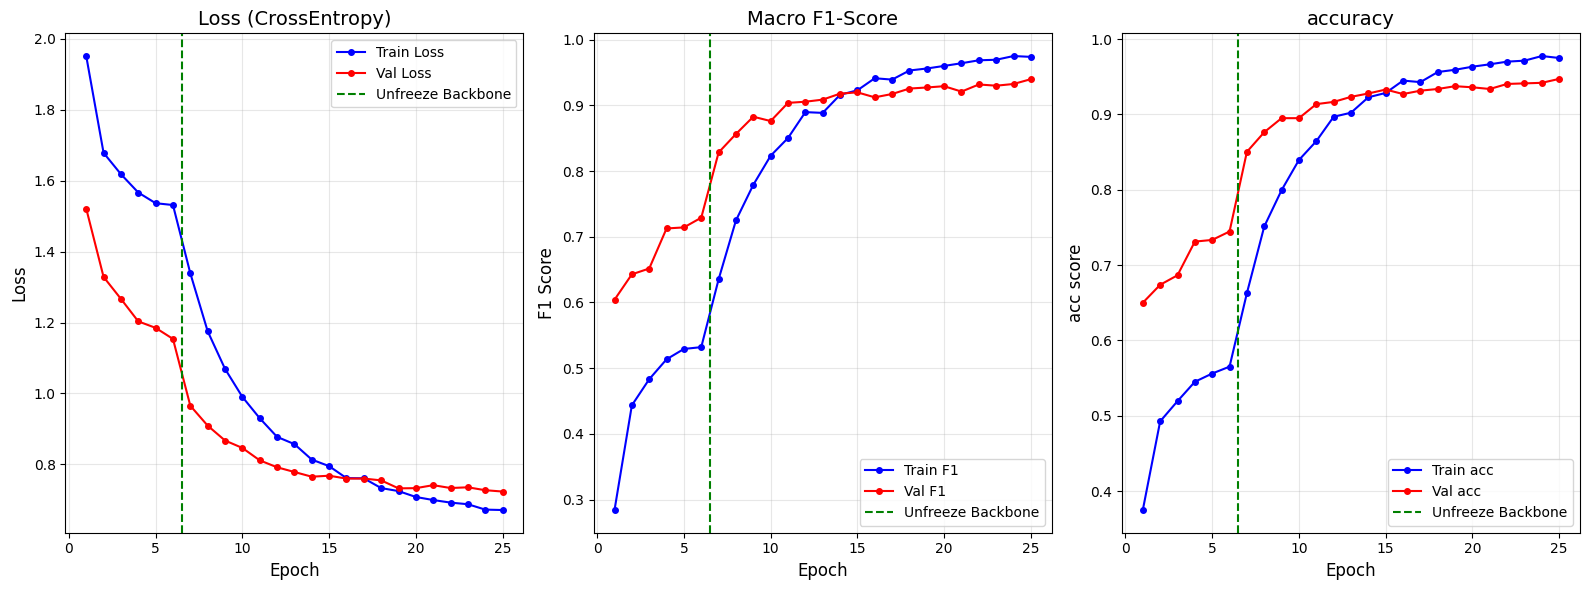

In [120]:
import matplotlib.pyplot as plt

def plot_history(history, stage1_epochs):
    epochs = range(1, len(history['train_loss']) + 1)
    
    plt.figure(figsize=(16, 6))
    
    # График Loss
    plt.subplot(1, 3, 1)
    plt.plot(epochs, history['train_loss'], 'b-o', label='Train Loss', markersize=4)
    plt.plot(epochs, history['val_loss'], 'r-o', label='Val Loss', markersize=4)
    plt.axvline(x=stage1_epochs + 0.5, color='green', linestyle='--', label='Unfreeze Backbone')
    plt.title('Loss (CrossEntropy)', fontsize=14)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.legend()
    
    # График Macro-F1
    plt.subplot(1, 3, 2)
    plt.plot(epochs, history['train_f1'], 'b-o', label='Train F1', markersize=4)
    plt.plot(epochs, history['val_f1'], 'r-o', label='Val F1', markersize=4)
    plt.axvline(x=stage1_epochs + 0.5, color='green', linestyle='--', label='Unfreeze Backbone')
    plt.title('Macro F1-Score', fontsize=14)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('F1 Score', fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.legend()

    # График accuracy
    plt.subplot(1, 3, 3)
    plt.plot(epochs, history['train_acc'], 'b-o', label='Train acc', markersize=4)
    plt.plot(epochs, history['val_acc'], 'r-o', label='Val acc', markersize=4)
    plt.axvline(x=stage1_epochs + 0.5, color='green', linestyle='--', label='Unfreeze Backbone')
    plt.title('accuracy', fontsize=14)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('acc score', fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.legend()
    
    plt.tight_layout()
    plt.show()

plot_history(history, STAGE1_EPOCHS)